# Textlänge

Abbildungen 11–14, 21/22; Tabelle 17. Wortzählung und inklusive Fenster wie im Generierungsprotokoll. R_obs=K/V, R_zero=K/20, R_adj=R_zero/(1+D); zuerst je Artikel, dann Mittelung.

In [1]:
from pathlib import Path
from fractions import Fraction
from collections import Counter
from itertools import combinations
import hashlib, importlib.metadata, json, math, platform, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display
from threadpoolctl import threadpool_limits
from faktenretention.io import PROJECT_ROOT
from faktenretention.data import load_inputs, panel, length_values, reconstruct_qa, aggregate_articles, CELL, KEY
from faktenretention.protocol import METHODS, STAGES, WINDOWS, CONTRASTS, LABELS
threadpool_limits(limits=1)
SEED, B, N_FACTS = (32, 10000, 20)
DATA_DIR = PROJECT_ROOT / 'data'
OUT = PROJECT_ROOT / 'results/03_textlaenge'
FIG = OUT
OUT.mkdir(parents=True, exist_ok=True)
COLORS = dict(zip(METHODS, ['#777777', '#0072B2', '#E69F00', '#009E73', '#CC79A7', '#D55E00']))
MARKERS = dict(zip(METHODS, ['o', 's', '^', 'D', 'v', 'P']))
LINESTYLES = dict(zip(METHODS, ['--', '-', '-.', '--', ':', '-']))
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_rows', 26)

def export(frame, name):
    frame.to_csv(OUT / f'{name}.csv', index=False)

def fmt(x, d=2):
    return f'{x:.{d}f}'.replace('.', ',')

def savefig(fig, name):
    fig.savefig(FIG / f'{name}.png', dpi=220, bbox_inches='tight')
    plt.show()
    plt.close(fig)

In [2]:
inputs = load_inputs()
qa, article = panel(inputs)
facts = inputs['facts']
summaries = inputs['summaries']
articles = inputs['articles']
IDS = sorted(articles.article_id)
assert len(IDS) == 100

## Wortfenster, tatsächliche Längen und Adjustierung

In [3]:
index_cache = {}
bootstrap_cache = {}
exact_cache = {}

def indices(ids):
    key = tuple(ids)
    if key not in index_cache:
        index_cache[key] = np.random.default_rng(SEED).integers(0, len(ids), size=(B, len(ids)))
    return index_cache[key]

def exact_value(row, metric):
    if metric == 'D':
        return Fraction(int(row.violation_words), int(row.stage_target_words))
    if metric == 'window_hit':
        return Fraction(int(row.window_hit), 1)
    if metric == 'R_obs':
        return Fraction(int(row.K), int(row.V))
    if metric == 'R_zero':
        return Fraction(int(row.K), N_FACTS)
    if metric == 'R_adj':
        return Fraction(int(row.K) * int(row.stage_target_words), N_FACTS * int(row.stage_target_words + row.violation_words))
    if metric == 'qa_denominator_gap':
        return exact_value(row, 'R_obs') - exact_value(row, 'R_zero')
    if metric == 'length_penalty':
        return exact_value(row, 'R_zero') - exact_value(row, 'R_adj')
    raise KeyError(metric)

def estimate_group(group, metric):
    group = group.sort_values('article_id')
    ids = tuple(group.article_id)
    key = (ids, group.method.iloc[0], int(group.stage_target_words.iloc[0]), metric)
    if key not in bootstrap_cache:
        point = sum((exact_value(row, metric) for row in group.itertuples()), Fraction(0)) / len(group)
        ix = indices(ids)
        if metric in ['R_obs', 'R_zero', 'D', 'window_hit']:
            fractions = [exact_value(row, metric) for row in group.itertuples()]
            denominator = math.lcm(*(v.denominator for v in fractions))
            numerator = np.array([v.numerator * (denominator // v.denominator) for v in fractions], dtype=np.int64)
            draws = numerator[ix].sum(axis=1) / (denominator * len(group))
        else:
            draws = group[metric].to_numpy(dtype=float)[ix].mean(axis=1)
        bootstrap_cache[key] = draws
        exact_cache[key] = point
    low, high = np.quantile(bootstrap_cache[key], [0.025, 0.975])
    return (float(exact_cache[key]), float(low), float(high), bootstrap_cache[key], exact_cache[key])

In [4]:
def tables_for(frame, scenario):
    rows = []
    for stage in STAGES:
        for method in METHODS:
            group = frame[(frame.method == method) & (frame.stage_target_words == stage)]
            assert set(group.article_id) == set(frame.article_id.unique())
            row = dict(scenario=scenario, method=method, stage_target_words=stage, n_articles=len(group),
                n_under=int(group.window_status.eq('under').sum()), n_within=int(group.window_hit.sum()),
                n_over=int(group.window_status.eq('over').sum()), n_empty=int(group.empty_output.sum()),
                n_empty_input=int(group.empty_input.sum()), n_chain_failure=int(group.chain_failure.sum()),
                W_mean=float(group.W.mean()), W_median=float(group.W.median()), W_p10=float(group.W.quantile(0.1)),
                W_p90=float(group.W.quantile(0.9)), W_min=int(group.W.min()), W_max=int(group.W.max()),
                D_median=float(group.D.median()), D_p90=float(group.D.quantile(0.9)), D_max=float(group.D.max()),
                under_words_mean=float(group.under_words.mean()), over_words_mean=float(group.over_words.mean()),
                under_D_mean=float(group.under_D.mean()), over_D_mean=float(group.over_D.mean()), n_missing_qa=int(group.n_missing.sum()),
                n_complete_sentences=int(group.complete_sentence.sum()))
            assert row['n_under'] + row['n_within'] + row['n_over'] == len(group)
            for status in ['under', 'within', 'over']:
                row[f'share_{status}'] = row[f'n_{status}'] / len(group)
            for metric in ['D', 'window_hit', 'R_obs', 'R_zero', 'R_adj', 'qa_denominator_gap', 'length_penalty']:
                mean, low, high, draws, exact = estimate_group(group, metric)
                row.update({f'{metric}_mean': mean, f'{metric}_ci_low': low, f'{metric}_ci_high': high})
                if metric.startswith('R_'):
                    row[f'{metric}_exact_mean'] = str(exact)
            rows.append(row)
    table = pd.DataFrame(rows)
    for metric in ['R_obs', 'R_zero', 'R_adj']:
        table[f'rank_{metric}'] = 0
        for stage in STAGES:
            selection = table.stage_target_words.eq(stage)
            exacts = [Fraction(s) for s in table.loc[selection, f'{metric}_exact_mean']]
            table.loc[selection, f'rank_{metric}'] = [1 + sum((other > value for other in exacts)) for value in exacts]
    table['rank_changed_H2'] = table.rank_R_obs.ne(table.rank_R_adj)
    table['rank_changed_denominator'] = table.rank_R_obs.ne(table.rank_R_zero)
    table['rank_changed_length'] = table.rank_R_zero.ne(table.rank_R_adj)
    return table
main = tables_for(article, 'main_100')

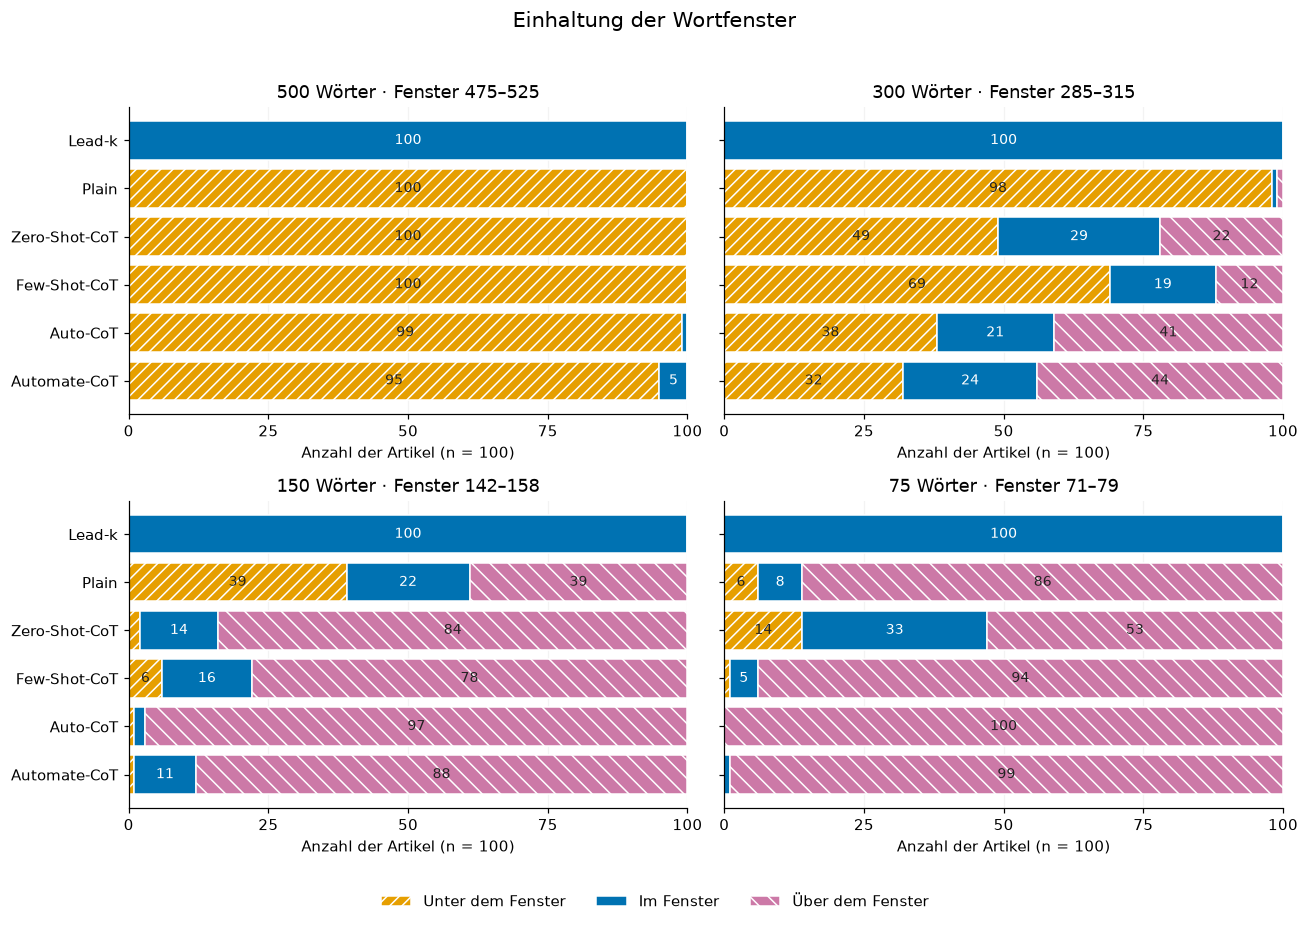

In [5]:
STATUS_COLORS = {'under': '#E69F00', 'within': '#0072B2', 'over': '#CC79A7'}
STATUS_LABELS = {'under': 'Unter dem Fenster', 'within': 'Im Fenster', 'over': 'Über dem Fenster'}
HATCHES = {'under': '///', 'within': '', 'over': '\\\\'}
fig, axes = plt.subplots(2, 2, figsize=(12, 8.6), sharex=True, sharey=True)
y = np.arange(len(METHODS))
for ax, stage in zip(axes.flat, STAGES):
    sub = main[main.stage_target_words.eq(stage)].set_index('method').loc[METHODS]
    left = np.zeros(len(METHODS))
    for status in ['under', 'within', 'over']:
        counts = sub[f'n_{status}'].to_numpy()
        ax.barh(y, counts, left=left, color=STATUS_COLORS[status], edgecolor='white', hatch=HATCHES[status],
            label=STATUS_LABELS[status])
        for i, n in enumerate(counts):
            if n >= 5:
                ax.text(left[i] + n / 2, y[i], str(n), ha='center', va='center', fontsize=9, color='white' if status == 'within' else '#222222')
        left += counts
    assert np.array_equal(left, np.full(6, 100))
    U, O = WINDOWS[stage]
    ax.set(title=f'{stage} Wörter · Fenster {U}–{O}', xlim=(0, 100), xticks=[0, 25, 50, 75, 100], yticks=y,
        yticklabels=[LABELS[m] for m in METHODS], xlabel='Anzahl der Artikel (n = 100)')
    ax.tick_params(axis='x', labelbottom=True)
    ax.set_axisbelow(True)
    ax.grid(axis='x', alpha=0.15)
axes[0, 0].invert_yaxis()
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, frameon=False, bbox_to_anchor=(0.5, 0.015))
fig.suptitle('Einhaltung der Wortfenster', fontsize=14)
fig.tight_layout(rect=(0, 0.07, 1, 0.96))
savefig(fig, 'abb_11_wortfenster')

In [6]:
length_columns = ['method', 'stage_target_words', 'n_articles', 'n_under', 'n_within', 'n_over', 'share_under',
    'share_within', 'share_over', 'W_mean', 'W_median', 'W_p10', 'W_p90', 'W_min', 'W_max', 'D_mean',
    'D_ci_low', 'D_ci_high', 'D_median', 'D_p90', 'D_max', 'under_words_mean', 'over_words_mean', 'under_D_mean',
    'over_D_mean', 'window_hit_ci_low', 'window_hit_ci_high', 'n_empty', 'n_empty_input', 'n_chain_failure']
length_table = main[length_columns]
export(length_table, 'laengeneinhaltung_24_gruppen')
presentation = main.assign(Verfahren=main.method.map(LABELS), **{'Unter / im / über': [f'{r.n_under} / {r.n_within} / {r.n_over}' for r in main.itertuples()],
    'D [95-%-Intervall]': [f'{fmt(r.D_mean, 3)} [{fmt(r.D_ci_low, 3)}; {fmt(r.D_ci_high, 3)}]' for r in main.itertuples()]})
display(presentation[['Verfahren', 'stage_target_words', 'Unter / im / über', 'W_mean', 'W_median', 'D [95-%-Intervall]',
    'D_median', 'D_p90', 'D_max', 'n_empty']].round(3))

,Verfahren,stage_target_words,Unter / im / über,W_mean,W_median,D [95-%-Intervall],D_median,D_p90,D_max,n_empty
0,Lead-k,500,0 / 100 / 0,500.00,500.0,"0,000 [0,000; 0,000]",0.000,0.000,0.000,0
1,Plain,500,100 / 0 / 0,209.31,209.5,"0,531 [0,513; 0,549]",0.531,0.654,0.708,0
2,Zero-Shot-CoT,500,100 / 0 / 0,345.29,344.5,"0,259 [0,240; 0,279]",0.261,0.390,0.504,0
3,Few-Shot-CoT,500,100 / 0 / 0,305.53,306.0,"0,339 [0,322; 0,355]",0.338,0.433,0.572,0
4,Auto-CoT,500,99 / 1 / 0,349.70,348.5,"0,251 [0,230; 0,272]",0.253,0.384,0.522,0
5,Automate-CoT,500,95 / 5 / 0,392.70,390.5,"0,166 [0,149; 0,182]",0.169,0.271,0.428,0
6,Lead-k,300,0 / 100 / 0,300.00,300.0,"0,000 [0,000; 0,000]",0.000,0.000,0.000,0
7,Plain,300,98 / 1 / 1,175.75,169.0,"0,368 [0,342; 0,392]",0.387,0.515,0.577,0
8,Zero-Shot-CoT,300,49 / 29 / 22,285.67,287.0,"0,070 [0,055; 0,086]",0.037,0.207,0.317,0
9,Few-Shot-CoT,300,69 / 19 / 12,270.07,269.5,"0,082 [0,067; 0,099]",0.058,0.197,0.387,0


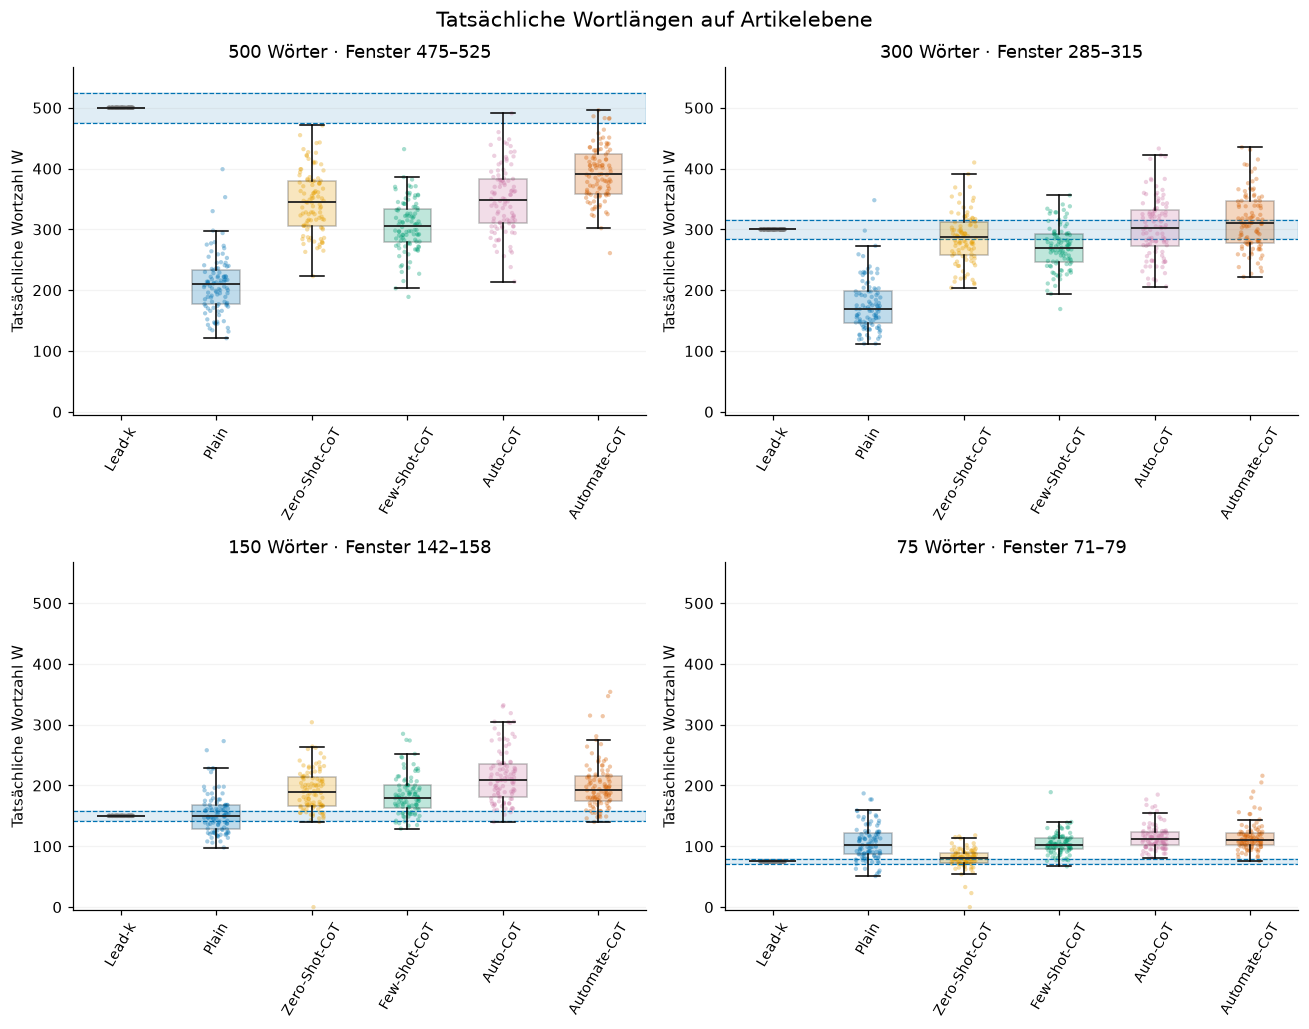

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9.5))
jitter = np.random.default_rng(SEED).uniform(-0.13, 0.13, size=len(IDS))
for ax, stage in zip(axes.flat, STAGES):
    U, O = WINDOWS[stage]
    ax.axhspan(U, O, color='#0072B2', alpha=0.12, zorder=0)
    ax.axhline(U, color='#0072B2', ls='--', lw=0.8)
    ax.axhline(O, color='#0072B2', ls='--', lw=0.8)
    arrays = [article[(article.method == m) & (article.stage_target_words == stage)].sort_values('article_id').W.to_numpy() for m in METHODS]
    boxes = ax.boxplot(arrays, positions=np.arange(6), patch_artist=True, widths=0.5, showfliers=False,
        medianprops={'color': '#222222', 'linewidth': 1.2})
    for j, (method, values) in enumerate(zip(METHODS, arrays)):
        boxes['boxes'][j].set_facecolor(COLORS[method])
        boxes['boxes'][j].set_alpha(0.25)
        ax.scatter(j + jitter, values, s=8, color=COLORS[method], alpha=0.35, edgecolors='none')
    ax.set(title=f'{stage} Wörter · Fenster {U}–{O}', ylabel='Tatsächliche Wortzahl W', xticks=np.arange(6),
        xticklabels=[LABELS[m] for m in METHODS], ylim=(-5, WINDOWS[500][1] * 1.08), yticks=np.arange(0, 501, 100))
    ax.tick_params(axis='x', labelrotation=60, labelsize=9)
    ax.grid(axis='y', alpha=0.15)
fig.suptitle('Tatsächliche Wortlängen auf Artikelebene', fontsize=14)
fig.tight_layout()
savefig(fig, 'abb_12_wortlaengen')

In [8]:
rank_display = pd.DataFrame(index=[LABELS[m] for m in METHODS], columns=STAGES)
for stage in STAGES:
    sub = main[main.stage_target_words.eq(stage)].set_index('method')
    for method in METHODS:
        row = sub.loc[method]
        rank_display.loc[LABELS[method], stage] = f'{row.rank_R_obs} → {row.rank_R_adj}' + (' *' if row.rank_changed_H2 else '')
rank_display.index.name = 'Verfahren'
rank_display.columns = [f'{stage} Wörter' for stage in STAGES]
display(rank_display)
retention_columns = ['method', 'stage_target_words', 'n_articles', 'n_missing_qa', 'R_obs_mean', 'R_obs_ci_low',
    'R_obs_ci_high', 'R_zero_mean', 'R_zero_ci_low', 'R_zero_ci_high', 'R_adj_mean', 'R_adj_ci_low',
    'R_adj_ci_high', 'qa_denominator_gap_mean', 'length_penalty_mean', 'rank_R_obs', 'rank_R_zero', 'rank_R_adj',
    'rank_changed_H2', 'rank_changed_denominator', 'rank_changed_length']
export(main[retention_columns], 'retention_und_drei_rangfolgen_24_gruppen')
display(main[retention_columns].round(6))

,500 Wörter,300 Wörter,150 Wörter,75 Wörter
Verfahren,,,,
Lead-k,1 → 1,6 → 5 *,6 → 6,6 → 6
Plain,6 → 6,5 → 6 *,5 → 5,4 → 5 *
Zero-Shot-CoT,3 → 3,3 → 2 *,3 → 1 *,5 → 2 *
Few-Shot-CoT,5 → 5,4 → 4,4 → 2 *,3 → 3
Auto-CoT,4 → 4,2 → 3 *,1 → 4 *,1 → 1
Automate-CoT,2 → 2,1 → 1,2 → 3 *,2 → 4 *


,method,stage_target_words,n_articles,n_missing_qa,R_obs_mean,R_obs_ci_low,R_obs_ci_high,R_zero_mean,R_zero_ci_low,R_zero_ci_high,...,R_adj_ci_low,R_adj_ci_high,qa_denominator_gap_mean,length_penalty_mean,rank_R_obs,rank_R_zero,rank_R_adj,rank_changed_H2,rank_changed_denominator,rank_changed_length
0,lead_k,500,100,5,0.755868,0.728315,0.782553,0.7540,0.726500,0.780500,...,0.726500,0.780500,0.001868,0.000000,1,1,1,False,False,False
1,plain,500,100,10,0.548915,0.515339,0.581148,0.5460,0.512500,0.578012,...,0.337219,0.385280,0.002915,0.184465,6,6,6,False,False,False
2,zero_shot_cot,500,100,7,0.718883,0.691412,0.745989,0.7165,0.689000,0.743500,...,0.549688,0.599583,0.002383,0.141818,3,3,3,False,False,False
3,few_shot_cot,500,100,16,0.641906,0.612117,0.670335,0.6370,0.607000,0.665500,...,0.454890,0.500418,0.004906,0.159092,5,5,5,False,False,False
4,auto_cot,500,100,12,0.713371,0.686136,0.739270,0.7095,0.682000,0.735500,...,0.548497,0.599263,0.003871,0.135581,4,4,4,False,False,False
5,automate_cot,500,100,11,0.733760,0.705974,0.760658,0.7300,0.702500,0.756500,...,0.604491,0.657778,0.003760,0.098885,2,2,2,False,False,False
6,lead_k,300,100,3,0.493684,0.466788,0.520395,0.4930,0.466000,0.520000,...,0.466000,0.520000,0.000684,0.000000,6,6,5,True,False,True
7,plain,300,100,10,0.500105,0.466526,0.532553,0.4975,0.464000,0.530000,...,0.344148,0.400709,0.002605,0.124588,5,5,6,True,False,True
8,zero_shot_cot,300,100,8,0.678535,0.650947,0.705457,0.6760,0.648000,0.703000,...,0.607880,0.664202,0.002535,0.039768,3,3,2,True,False,True
9,few_shot_cot,300,100,7,0.610427,0.580605,0.639743,0.6080,0.578500,0.637000,...,0.536484,0.592518,0.002427,0.043323,4,4,4,False,False,False


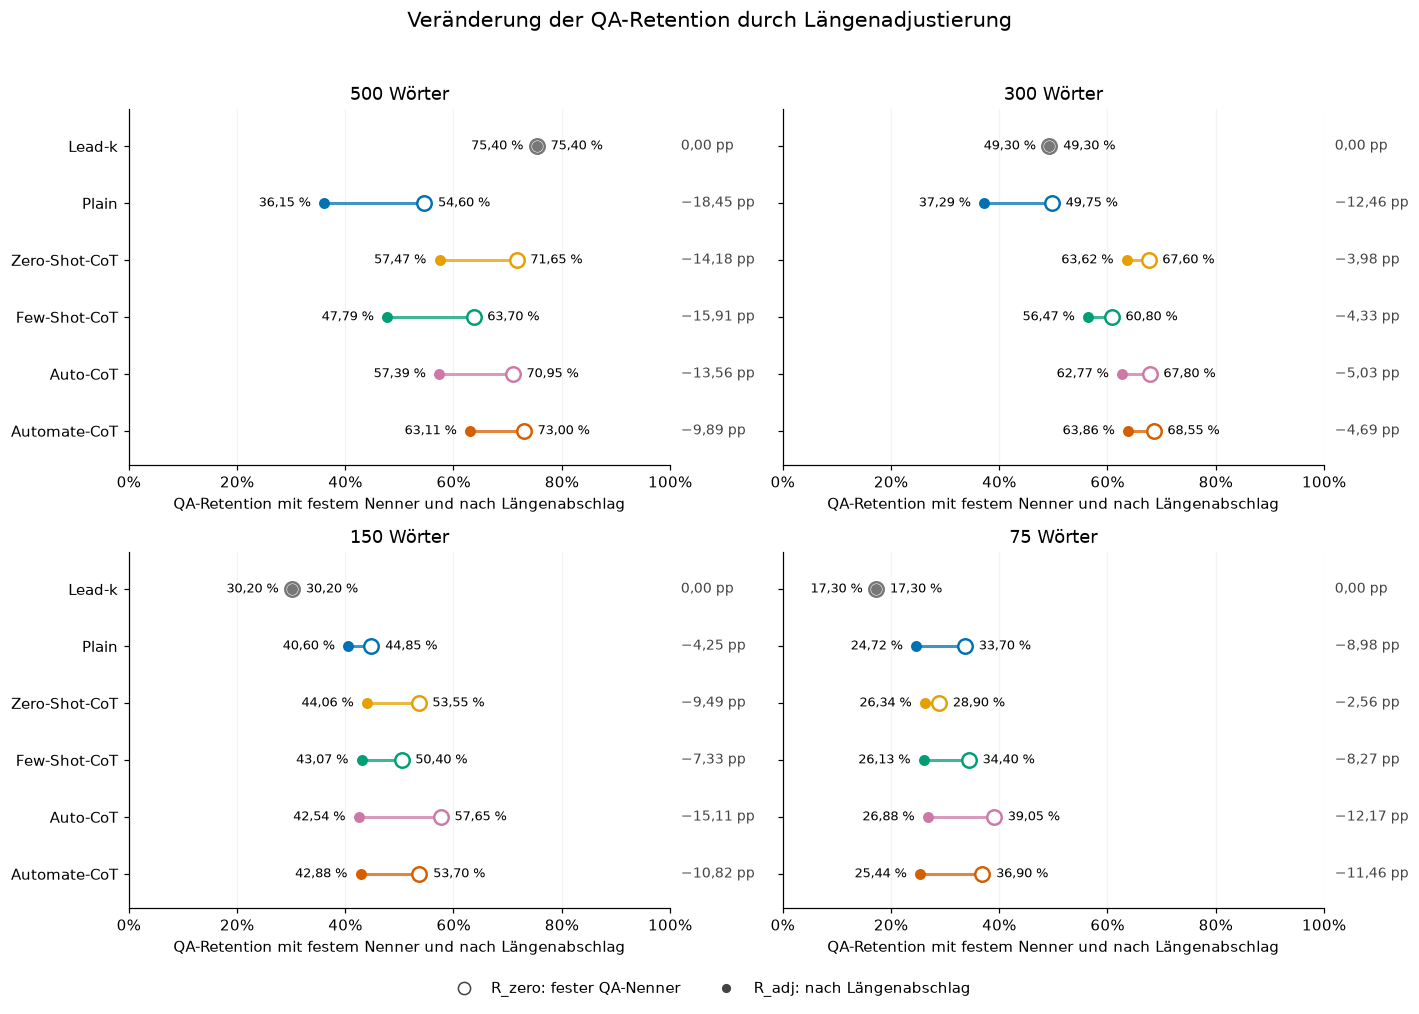

In [9]:
from matplotlib.lines import Line2D
fig, axes = plt.subplots(2, 2, figsize=(13, 9.5), sharex=True, sharey=True)
y = np.arange(len(METHODS))
for ax, stage in zip(axes.flat, STAGES):
    sub = main[main.stage_target_words.eq(stage)].set_index('method').loc[METHODS]
    for i, method in enumerate(METHODS):
        row = sub.loc[method]
        before, after = (100 * row.R_zero_mean, 100 * row.R_adj_mean)
        assert before >= after
        ax.plot([after, before], [i, i], color=COLORS[method], lw=2, alpha=0.75, zorder=2)
        ax.scatter(before, i, s=90, facecolors='white', edgecolors=COLORS[method], linewidths=1.6, zorder=3)
        ax.scatter(after, i, s=38, color=COLORS[method], zorder=4)
        ax.annotate(f'{fmt(after)} %', xy=(after, i), xytext=(-9, 0), textcoords='offset points', ha='right',
            va='center', fontsize=8.5)
        ax.annotate(f'{fmt(before)} %', xy=(before, i), xytext=(9, 0), textcoords='offset points', ha='left',
            va='center', fontsize=8.5)
        penalty = before - after
        label = f'−{fmt(penalty)} pp' if penalty > 0 else '0,00 pp'
        ax.text(1.02, i, label, transform=ax.get_yaxis_transform(), ha='left', va='center', fontsize=9, color='#444444')
    ax.set(title=f'{stage} Wörter', xlim=(0, 100), ylim=(-0.65, len(METHODS) - 0.4), xticks=[0, 20, 40,
        60, 80, 100], yticks=y, yticklabels=[LABELS[m] for m in METHODS], xlabel='QA-Retention mit festem Nenner und nach Längenabschlag')
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
    ax.tick_params(axis='x', labelbottom=True)
    ax.set_axisbelow(True)
    ax.grid(axis='x', alpha=0.15)
axes[0, 0].invert_yaxis()
handles = [Line2D([], [], marker='o', ls='none', mfc='white', mec='#444444', ms=8, label='R_zero: fester QA-Nenner'),
    Line2D([], [], marker='o', ls='none', mfc='#444444', mec='#444444', ms=5, label='R_adj: nach Längenabschlag')]
fig.legend(handles=handles, loc='lower center', ncol=2, frameon=False, bbox_to_anchor=(0.5, 0.023))
fig.suptitle('Veränderung der QA-Retention durch Längenadjustierung', fontsize=14)
fig.tight_layout(rect=(0, 0.06, 1, 0.96))
savefig(fig, 'abb_13_laengenadjustierung')

## Berichtete Rangwechsel, Spannweiten und gepaarte Abstände

Zusätzlich bleibt ausschließlich der im Text genannte Vergleich bei 75 Wörtern nach Ausschluss der beiden Artikel mit leeren Ausgaben (n=98) erhalten.

Technischer Prüfpunkt: Der im Manuskript mit 0,08 pp genannte 500-Wort-Abstand betrifft Zero-Shot-CoT–Auto-CoT; diese sind dort nicht die beiden führenden generativen Verfahren.

In [10]:
def pairwise_for(frame, scenario):
    rows = []
    for stage in STAGES:
        for first, second in combinations(METHODS, 2):
            left = frame[(frame.method == first) & (frame.stage_target_words == stage)].sort_values('article_id')
            right = frame[(frame.method == second) & (frame.stage_target_words == stage)].sort_values('article_id')
            assert left.article_id.tolist() == right.article_id.tolist()
            row = dict(scenario=scenario, stage_target_words=stage, first=first, second=second, n_articles=len(left))
            for metric in ['R_obs', 'R_zero', 'R_adj', 'D']:
                lm, ll, lh, ld, le = estimate_group(left, metric)
                rm, rl, rh, rd, rex = estimate_group(right, metric)
                delta = ld - rd
                low, high = np.quantile(delta, [0.025, 0.975])
                multiplier = 1 if metric == 'D' else 100
                row.update({f'delta_{metric}': float(le - rex) * multiplier, f'delta_{metric}_ci_low': float(low) * multiplier,
                    f'delta_{metric}_ci_high': float(high) * multiplier})
                if metric != 'D':
                    difference = le - rex
                    row[f'order_{metric}'] = 1 if difference > 0 else -1 if difference < 0 else 0
            row['order_changed_H2'] = row['order_R_obs'] != row['order_R_adj']
            row['order_changed_denominator'] = row['order_R_obs'] != row['order_R_zero']
            row['order_changed_length'] = row['order_R_zero'] != row['order_R_adj']
            rows.append(row)
    return pd.DataFrame(rows)
pairs = pairwise_for(article, 'main_100')
changes = pairs[pairs.order_changed_H2]
export(changes[['stage_target_words', 'first', 'second', 'delta_R_obs', 'delta_R_zero', 'delta_R_adj',
    'delta_R_adj_ci_low', 'delta_R_adj_ci_high', 'order_changed_denominator', 'order_changed_length']],
    'rangwechsel_gepaarte_intervalle')
reported = []
for stage in STAGES:
    first, second = {500:('zero_shot_cot','auto_cot'),300:('automate_cot','zero_shot_cot'),150:('zero_shot_cot',
        'few_shot_cot'),75:('auto_cot','zero_shot_cot')}[stage]
    left = article[article.method.eq(first) & article.stage_target_words.eq(stage)]
    right = article[article.method.eq(second) & article.stage_target_words.eq(stage)]
    lm, ll, lh, ld, le = estimate_group(left, 'R_adj')
    rm, rl, rh, rd, rex = estimate_group(right, 'R_adj')
    low, high = np.quantile(100 * (ld - rd), [0.025, 0.975])
    reported.append(dict(stage_target_words=stage, first=first, second=second, n_articles=100, difference_pp=100 * float(le - rex),
        ci_low_pp=low, ci_high_pp=high))
without_empty = article[~article.article_id.isin(article.loc[article.empty_output, 'article_id'].unique())]
assert without_empty.article_id.nunique() == 98
left = without_empty[without_empty.method.eq('zero_shot_cot') & without_empty.stage_target_words.eq(75)]
right = without_empty[without_empty.method.eq('auto_cot') & without_empty.stage_target_words.eq(75)]
lm, ll, lh, ld, le = estimate_group(left, 'R_adj')
rm, rl, rh, rd, rex = estimate_group(right, 'R_adj')
low, high = np.quantile(100 * (ld - rd), [0.025, 0.975])
reported.append(dict(stage_target_words=75, first='zero_shot_cot', second='auto_cot', n_articles=98, difference_pp=100 * float(le - rex),
    ci_low_pp=low, ci_high_pp=high))
export(pd.DataFrame(reported), 'berichtete_adjustierte_abstaende_100_98')
ranges = main[main.method.ne('lead_k')].groupby('stage_target_words')[['R_zero_mean', 'R_adj_mean']].agg(lambda x: 100 * (x.max() - x.min())).reset_index()
export(ranges, 'spannweiten_generativer_mittelwerte_pp')
display(pd.DataFrame(reported).round(4))

,stage_target_words,first,second,n_articles,difference_pp,ci_low_pp,ci_high_pp
0,500,zero_shot_cot,auto_cot,100,0.0764,-1.9517,2.0824
1,300,automate_cot,zero_shot_cot,100,0.2390,-2.1765,2.6200
2,150,zero_shot_cot,few_shot_cot,100,0.9903,-1.4954,3.4306
3,75,auto_cot,zero_shot_cot,100,0.5432,-1.6341,2.7735
4,75,zero_shot_cot,auto_cot,98,0.0752,-1.9388,2.0490


## Matching desselben Artikels und derselben Stufe

Auswahl ausschließlich nach Wortzahl: `40*abs(W_A-W_B) <= W_A+W_B`, mittlere Wortzahl >0. Gepaarte 95-%-Perzentilintervalle bei fixer Auswahl; je Vergleich deterministischer Teilstrom von Seed 32. Unterschiedliche Paare können unterschiedliche Artikelmengen verwenden.

In [11]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.patches import Rectangle
NAMES = LABELS
KEY = CELL
article_values = article[CELL + ['W', 'n_valid', 'n_retained', 'R_obs']].rename(columns={'R_obs': 'R'})

In [12]:
pair_results, audit_parts, boot_distributions = ([], [], {})
for target in STAGES:
    stage_data = article_values[article_values.stage_target_words.eq(target)]
    for i, j in combinations(range(len(METHODS)), 2):
        method_a, method_b = (METHODS[i], METHODS[j])
        left = stage_data[stage_data.method.eq(method_a)][['article_id', 'W', 'R', 'n_valid', 'n_retained']]
        right = stage_data[stage_data.method.eq(method_b)][['article_id', 'W', 'R', 'n_valid', 'n_retained']]
        pairs = left.merge(right, on='article_id', suffixes=('_row', '_column'), validate='one_to_one').sort_values('article_id')
        assert len(pairs) == len(IDS)
        total_words = pairs.W_row + pairs.W_column
        word_difference = (pairs.W_row - pairs.W_column).abs()
        pairs['mean_word_count'] = total_words / 2
        pairs['relative_word_difference'] = 2 * word_difference / total_words.replace(0, np.nan)
        pairs['length_eligible'] = total_words.gt(0) & (40 * word_difference).le(total_words)
        pairs['qa_available'] = pairs.n_valid_row.gt(0) & pairs.n_valid_column.gt(0) & np.isfinite(pairs.R_row) & np.isfinite(pairs.R_column)
        pairs['included'] = pairs.length_eligible & pairs.qa_available
        pairs['delta_pp'] = 100 * (pairs.R_row - pairs.R_column)
        pairs['stage_target_words'] = target
        pairs['row_method'], pairs['column_method'] = (method_a, method_b)
        pairs['exclusion_reason'] = np.select([total_words.eq(0), ~pairs.length_eligible, ~pairs.qa_available],
            ['mittlere Wortzahl null', 'Wortzahldifferenz über 5 %', 'ungültiger QA-Nenner oder fehlende Retention'],
            default='berücksichtigt')
        audit_parts.append(pairs)
        selected = pairs.loc[pairs.included, 'delta_pp'].to_numpy(dtype=float)
        n = len(selected)
        mean = float(selected.mean()) if n else np.nan
        lo = hi = np.nan
        if n >= 2:
            rng = np.random.default_rng(np.random.SeedSequence([SEED, target, i, j]))
            indices = rng.integers(0, n, size=(B, n))
            boot_means = selected[indices].mean(axis=1)
            lo, hi = np.quantile(boot_means, [0.025, 0.975], method='linear')
            boot_distributions[f'stage{target}_pair{i}_{j}'] = boot_means
        pair_results.append({'stage_target_words': target, 'row_method': method_a, 'column_method': method_b,
            'mean_delta_pp': mean, 'n': n, 'ci95_low_pp': lo, 'ci95_high_pp': hi, 'small_sample': 0 < n < 10,
            'n_length_eligible': int(pairs.length_eligible.sum()), 'n_qa_unavailable_after_length': int((pairs.length_eligible & ~pairs.qa_available).sum()),
            'n_zero_mean_words': int(total_words.eq(0).sum())})
comparisons = pd.DataFrame(pair_results)
pair_audit = pd.concat(audit_parts, ignore_index=True)
assert len(comparisons) == 60 and len(pair_audit) == 6000
mirrored = comparisons.copy()
mirrored['row_method'], mirrored['column_method'] = (comparisons.column_method, comparisons.row_method)
mirrored['mean_delta_pp'] = -comparisons.mean_delta_pp
mirrored['ci95_low_pp'], mirrored['ci95_high_pp'] = (-comparisons.ci95_high_pp, -comparisons.ci95_low_pp)
matrix_cells = pd.concat([comparisons, mirrored], ignore_index=True)
assert len(matrix_cells) == 120
comparisons.to_csv(OUT / 'bootstrap_intervalle_60_eindeutige_vergleiche.csv', index=False)
matrix_cells.to_csv(OUT / 'matrixzellen_120_gerichtete_vergleiche.csv', index=False)
pass
maximum = matrix_cells.mean_delta_pp.abs().max()
COLOR_LIMIT = max(5, 5 * math.ceil(maximum / 5)) if pd.notna(maximum) else 5
CMAP = LinearSegmentedColormap.from_list('signed_retention', ['#a84921', '#fafafa', '#12568a'])
NORM = TwoSlopeNorm(vmin=-COLOR_LIMIT, vcenter=0, vmax=COLOR_LIMIT)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 12, 'axes.titlesize': 18, 'svg.fonttype': 'none',
    'savefig.facecolor': 'white'})
summary = comparisons.groupby('stage_target_words', sort=False).agg(Vergleiche=('n', 'size'), Ohne_Vergleich=('n',
    lambda s: int(s.eq(0).sum())), Kleine_Stichprobe=('small_sample', 'sum'), Min_n=('n', 'min'), Max_n=('n', 'max'))
display(summary)

,Vergleiche,Ohne_Vergleich,Kleine_Stichprobe,Min_n,Max_n
stage_target_words,,,,,
500,15,5,5,0,29
300,15,1,4,0,29
150,15,0,5,2,20
75,15,1,6,0,23


In [13]:
def de_number(value, signed=True):
    if pd.isna(value):
        return '—'
    if abs(value) < 0.005:
        value = 0.0
    return (f'{value:+.2f}' if signed else f'{value:.2f}').replace('.', ',').replace('-', '−')

def draw_matrix(target, save=True):
    lookup = matrix_cells[matrix_cells.stage_target_words.eq(target)].set_index(['row_method', 'column_method'])
    values = np.full((6, 6), np.nan)
    fig, ax = plt.subplots(figsize=(12.2, 10.5))
    for i, method_row in enumerate(METHODS):
        for j, method_column in enumerate(METHODS):
            if i != j:
                values[i, j] = lookup.loc[(method_row, method_column), 'mean_delta_pp']
    cmap = CMAP.copy()
    cmap.set_bad('white')
    image = ax.imshow(np.ma.masked_invalid(values), cmap=cmap, norm=NORM, interpolation='nearest')
    for i, method_row in enumerate(METHODS):
        for j, method_column in enumerate(METHODS):
            if i == j:
                continue
            row = lookup.loc[method_row, method_column]
            if row.n == 0:
                ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, facecolor='#dedede', edgecolor='white', linewidth=1.5))
                ax.text(j, i, 'kein\nVergleich', ha='center', va='center', fontsize=11, color='#343434')
            else:
                value = row.mean_delta_pp
                rgb = CMAP(NORM(value))[:3]

                def linear_channel(channel):
                    return channel / 12.92 if channel <= 0.04045 else ((channel + 0.055) / 1.055) ** 2.4
                luminance = sum((w * linear_channel(v) for w, v in zip([0.2126, 0.7152, 0.0722], rgb)))
                text_color = 'white' if (luminance + 0.05) / 0.05 < 4.5 else '#171717'
                marker = ' †' if row.small_sample else ''
                ax.text(j, i, f'{de_number(value)} PP\nn = {int(row.n)}{marker}', ha='center', va='center',
                    fontsize=11.5, color=text_color, linespacing=1.5)
                if row.small_sample:
                    ax.add_patch(Rectangle((j - 0.44, i - 0.44), 0.88, 0.88, fill=False, edgecolor=text_color,
                        linewidth=1.1, linestyle=(0, (3, 3))))
    ax.set_xticks(range(6), [NAMES[m] for m in METHODS], rotation=32, ha='left', rotation_mode='anchor')
    ax.set_yticks(range(6), [NAMES[m] for m in METHODS])
    ax.xaxis.tick_top()
    ax.tick_params(axis='both', which='both', length=0, pad=9, labelsize=12)
    ax.set_xticks(np.arange(-0.5, 6, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 6, 1), minor=True)
    ax.grid(which='minor', color='white', linewidth=1.5)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_title(f'Zielstufe {target} Wörter', loc='left', pad=108)
    fig.text(0.07, 0.952, 'QA-Faktenretention bei höchstens 5 % Wortzahldifferenz', fontsize=13, color='#333333')
    colorbar = fig.colorbar(image, ax=ax, fraction=0.044, pad=0.04, shrink=0.95)
    colorbar.set_label('Mittlere Differenz: Zeile − Spalte (Prozentpunkte)', fontsize=12, labelpad=12)
    ticks = np.linspace(-COLOR_LIMIT, COLOR_LIMIT, 5)
    colorbar.set_ticks(ticks, labels=[de_number(x, signed=False) for x in ticks])
    colorbar.outline.set_visible(False)
    fig.text(0.07, 0.105, 'Blau / positiv: Zeilenverfahren höher · Orange / negativ: Spaltenverfahren höher', fontsize=11)
    fig.text(0.07, 0.077, '† und gestrichelter Rahmen: n < 10; Hinweis auf kleine Stichprobe, keine feste Belastbarkeitsgrenze.', fontsize=10.5)
    fig.text(0.07, 0.052, 'Grau: kein Vergleich · Diagonale leer · Retention ohne Längenabschlag · Daten: aktuell_20260930', fontsize=10.5)
    fig.subplots_adjust(left=0.215, right=0.9, top=0.77, bottom=0.16)
    if save:
        for extension in ['png']:
            fig.savefig(FIG / f'abb_{(21 if target == 500 else 22)}_matching_{target}.{extension}', dpi=180)
    return fig

def interval_table(target):
    current = comparisons[comparisons.stage_target_words.eq(target)].copy()
    shown = pd.DataFrame({'Zeilenverfahren': current.row_method.map(NAMES), 'Spaltenverfahren': current.column_method.map(NAMES),
        'ΔR (PP)': current.mean_delta_pp.map(de_number), 'n': current.n, '95-%-Perzentilintervall (PP)': [f'[{de_number(lo)}; {de_number(hi)}]' if n >= 2 else 'kein Intervall (n < 2)' for lo,
        hi, n in current[['ci95_low_pp', 'ci95_high_pp', 'n']].itertuples(index=False, name=None)], 'Hinweis': ['kein Vergleich' if n == 0 else '† kleine Stichprobe' if n < 10 else '' for n in current.n]})
    shown.to_csv(OUT / f'intervalltabelle_{target}_woerter_formatiert.csv', index=False)
    return shown.reset_index(drop=True)

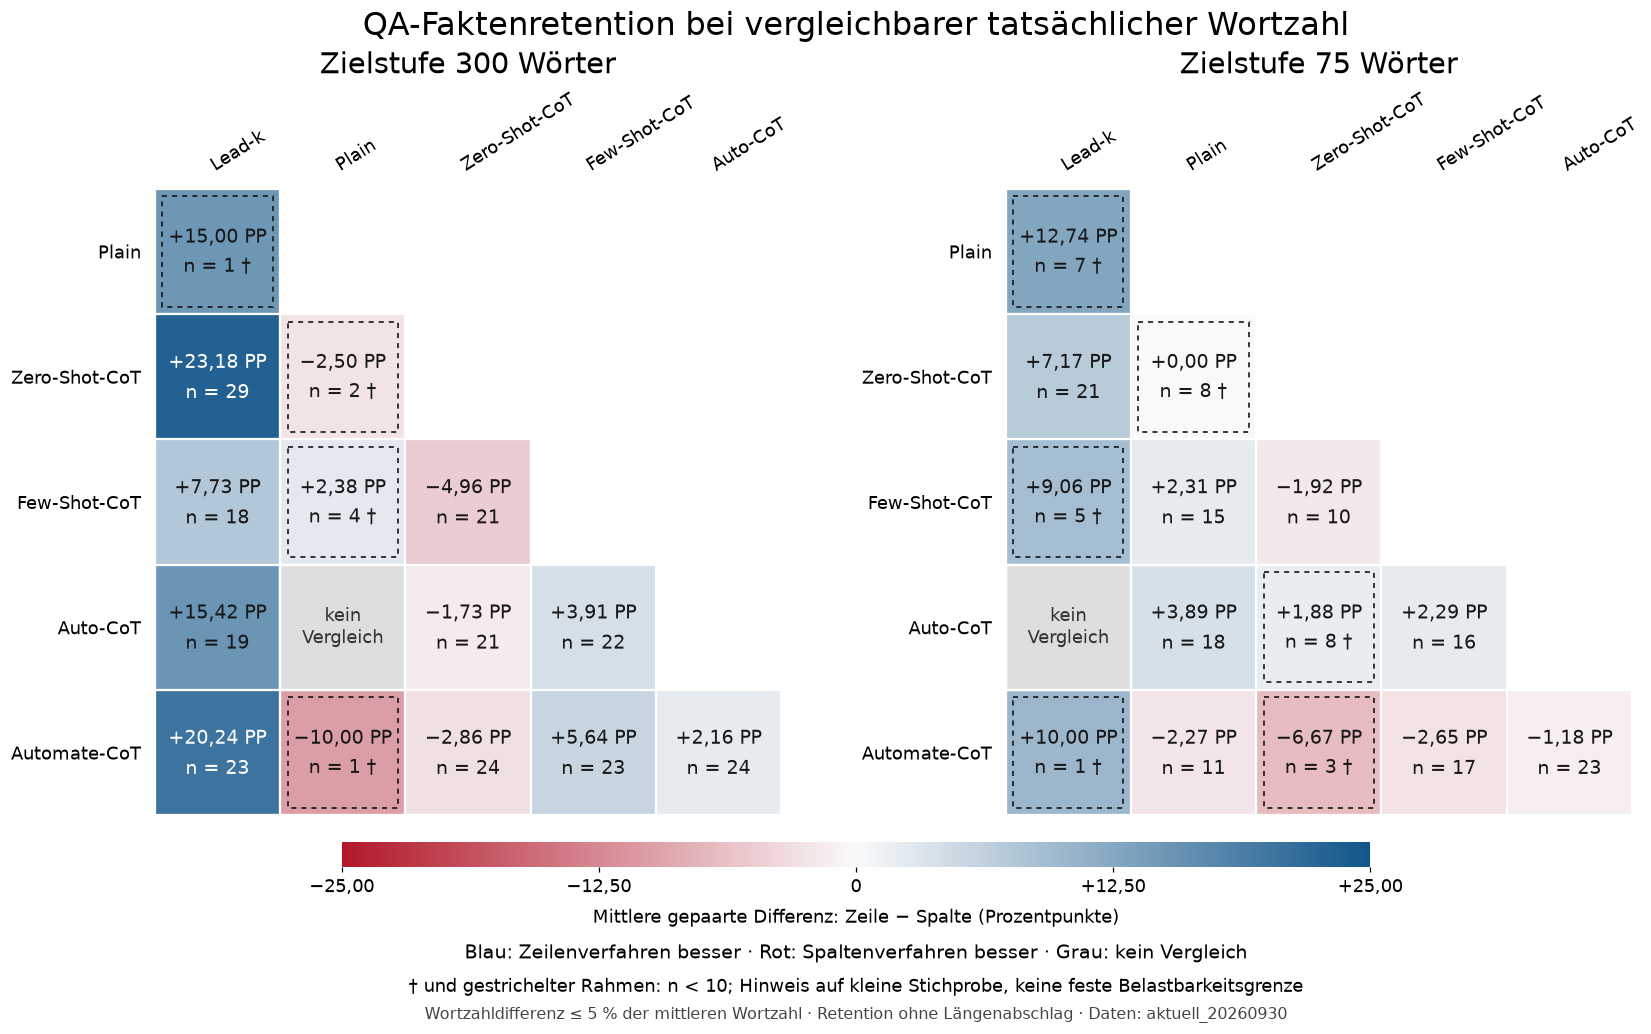

In [14]:
"""Plot the lower triangles of the reviewed 300- and 75-word matrices together."""
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.patches import Rectangle

def draw_combined_matrices(matrix_cells, color_limits, export_dir=None):
    methods = ['lead_k', 'plain', 'zero_shot_cot', 'few_shot_cot', 'auto_cot', 'automate_cot']
    names = ['Lead-k', 'Plain', 'Zero-Shot-CoT', 'Few-Shot-CoT', 'Auto-CoT', 'Automate-CoT']
    vmin, vmax = color_limits
    norm = TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)
    cmap = LinearSegmentedColormap.from_list('signed_retention_red_blue', ['#b2182b', '#fafafa', '#12568a'])
    cmap.set_bad('white')
    plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 12, 'svg.fonttype': 'none'})

    def number(value):
        if abs(value) < 0.005:
            value = 0.0
        return f'{value:+.2f}'.replace('.', ',').replace('-', '−')

    def text_color(value):
        rgb = cmap(norm(value))[:3]
        linear = [c / 12.92 if c <= 0.04045 else ((c + 0.055) / 1.055) ** 2.4 for c in rgb]
        luminance = sum((w * c for w, c in zip([0.2126, 0.7152, 0.0722], linear)))
        return 'white' if (luminance + 0.05) / 0.05 < 4.5 else '#171717'
    fig = plt.figure(figsize=(17, 9.5), facecolor='white')
    for target, left in [(300, 0.125), (75, 0.58)]:
        width, bottom, height = (0.335, 0.21, 0.335 * 17 / 9.5)
        ax = fig.add_axes([left, bottom, width, height])
        stage = matrix_cells[matrix_cells.stage_target_words.eq(target)].set_index(['row_method', 'column_method'])
        assert len(stage) == 30 and (not stage.index.duplicated().any())
        values = np.full((5, 5), np.nan)
        shown_pairs = []
        for i, row_method in enumerate(methods[1:]):
            for j, column_method in enumerate(methods[:-1]):
                if j <= i:
                    row = stage.loc[row_method, column_method]
                    values[i, j] = row.mean_delta_pp
                    shown_pairs.append(frozenset([row_method, column_method]))
        assert len(shown_pairs) == len(set(shown_pairs)) == 15
        image = ax.imshow(np.ma.masked_invalid(values), cmap=cmap, norm=norm, interpolation='nearest')
        for i, row_method in enumerate(methods[1:]):
            for j, column_method in enumerate(methods[:-1]):
                if j > i:
                    continue
                row = stage.loc[row_method, column_method]
                if row.n == 0:
                    ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, facecolor='#dedede', edgecolor='white', linewidth=1.5))
                    ax.text(j, i, 'kein\nVergleich', ha='center', va='center', fontsize=12, color='#343434')
                    continue
                color = text_color(row.mean_delta_pp)
                small = 0 < row.n < 10
                marker = ' †' if small else ''
                ax.text(j, i, f'{number(row.mean_delta_pp)} PP\nn = {int(row.n)}{marker}', ha='center',
                    va='center', fontsize=12.5, color=color, linespacing=1.5)
                if small:
                    ax.add_patch(Rectangle((j - 0.44, i - 0.44), 0.88, 0.88, fill=False, edgecolor=color,
                        linewidth=1.1, linestyle=(0, (3, 3))))
        ax.set_xticks(range(5), names[:-1], rotation=32, ha='left', rotation_mode='anchor')
        ax.set_yticks(range(5), names[1:])
        ax.xaxis.tick_top()
        ax.tick_params(axis='both', which='both', length=0, pad=9, labelsize=12)
        ax.set_xticks(np.arange(-0.5, 5, 1), minor=True)
        ax.set_yticks(np.arange(-0.5, 5, 1), minor=True)
        ax.grid(which='minor', color='white', linewidth=1.5)
        for spine in ax.spines.values():
            spine.set_visible(False)
        fig.text(left + width / 2, 0.92, f'Zielstufe {target} Wörter', ha='center', fontsize=19)
    fig.suptitle('QA-Faktenretention bei vergleichbarer tatsächlicher Wortzahl', x=0.5, y=0.98, fontsize=21)
    cax = fig.add_axes([0.225, 0.16, 0.55, 0.024])
    colorbar = fig.colorbar(image, cax=cax, orientation='horizontal')
    ticks = np.linspace(vmin, vmax, 5)
    colorbar.set_ticks(ticks, labels=[number(x) if x else '0' for x in ticks])
    colorbar.set_label('Mittlere gepaarte Differenz: Zeile − Spalte (Prozentpunkte)', fontsize=12, labelpad=8)
    colorbar.outline.set_visible(False)
    fig.text(0.5, 0.073, 'Blau: Zeilenverfahren besser · Rot: Spaltenverfahren besser · Grau: kein Vergleich',
        ha='center', fontsize=12.5)
    fig.text(0.5, 0.041, '† und gestrichelter Rahmen: n < 10; Hinweis auf kleine Stichprobe, keine feste Belastbarkeitsgrenze',
        ha='center', fontsize=11.5)
    fig.text(0.5, 0.015, 'Wortzahldifferenz ≤ 5 % der mittleren Wortzahl · Retention ohne Längenabschlag · Daten: aktuell_20260930',
        ha='center', fontsize=10.5, color='#444444')
    if export_dir is not None:
        for extension in ['png']:
            path = Path(export_dir) / f'abb_14_matching_300_75.{extension}'
            fig.savefig(path, dpi=220, facecolor='white')
    return fig
combined_figure = draw_combined_matrices(matrix_cells, (-COLOR_LIMIT, COLOR_LIMIT), FIG)
plt.show()
plt.close(combined_figure)

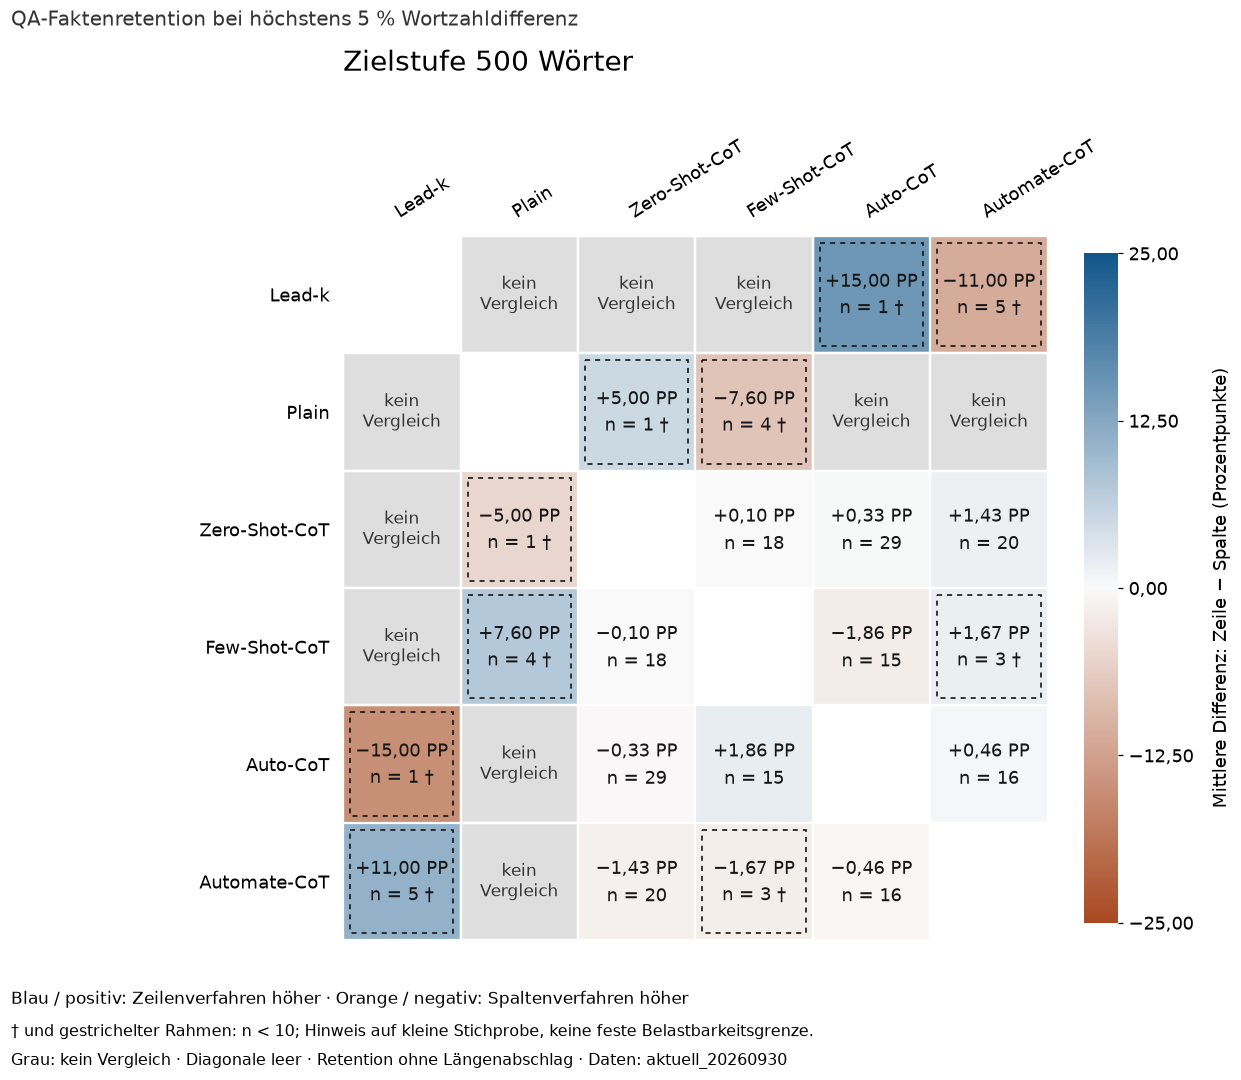

In [15]:
figure = draw_matrix(500)
plt.show()
plt.close(figure)

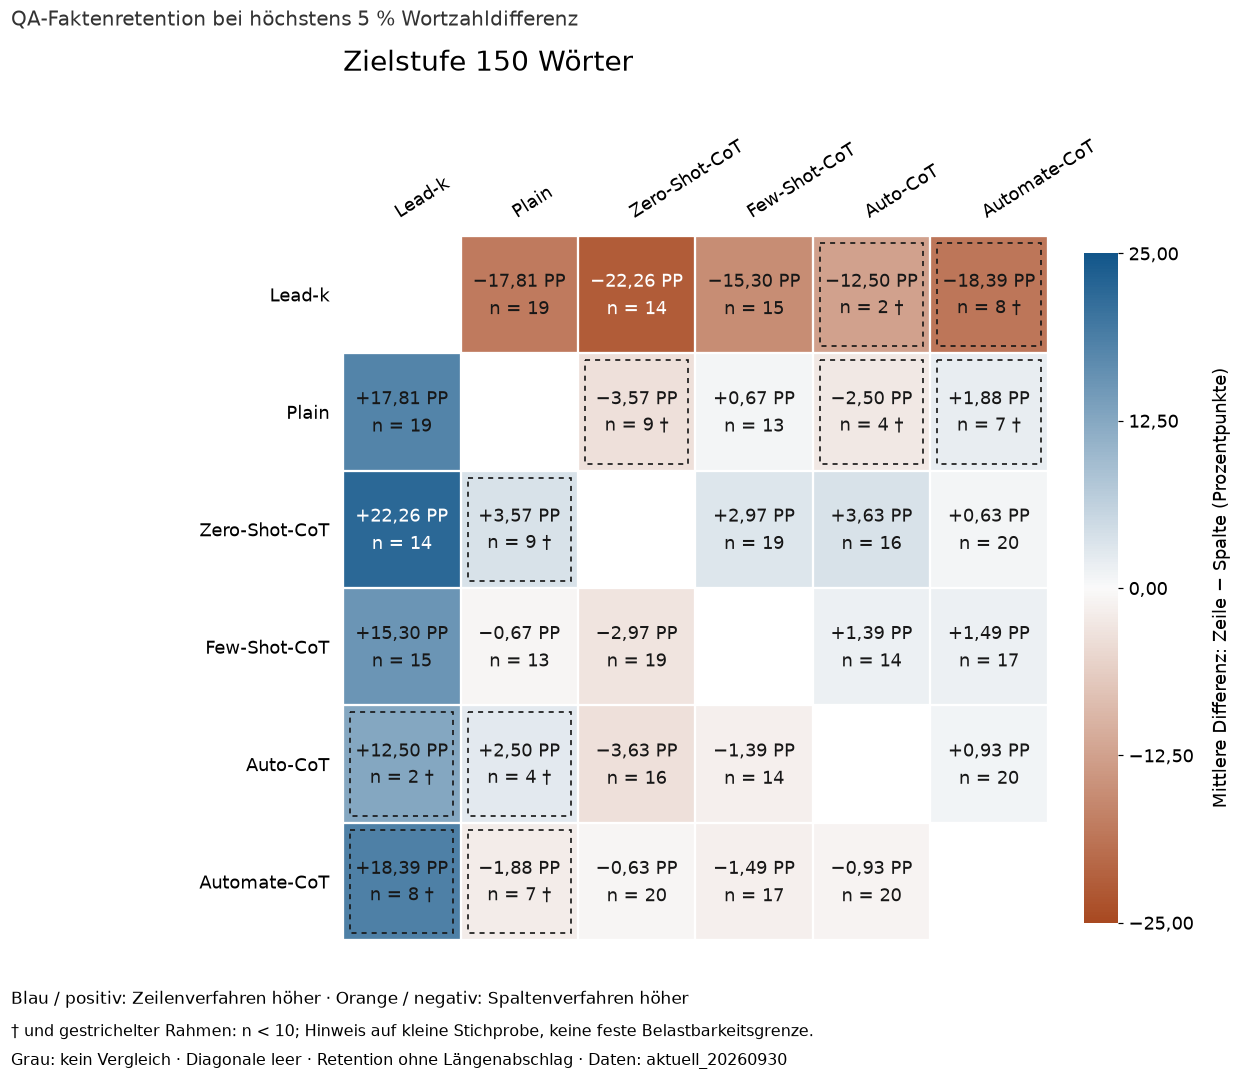

In [16]:
figure = draw_matrix(150)
plt.show()
plt.close(figure)